In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from google.colab import files
uploaded = files.upload()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv


In [3]:

import pandas as pd

# Load the uploaded dataset
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nChurn counts:")
print(df["Churn"].value_counts())

print("\nMissing values:")
print(df.isnull().sum().sum())


Dataset loaded successfully!
Dataset shape: (7043, 21)

First 5 rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  70

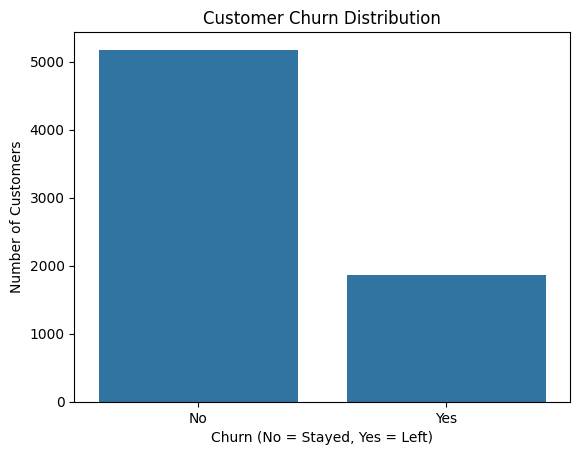

In [4]:

import matplotlib.pyplot as plt
import seaborn as sns

# Count customers who stayed and left
sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn (No = Stayed, Yes = Left)")
plt.ylabel("Number of Customers")
plt.show()


In [5]:

# Make a copy of the dataset
df_clean = df.copy()

# Convert TotalCharges to numeric
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

# Check missing values after conversion
print("Missing values after conversion:")
print(df_clean["TotalCharges"].isnull().sum())

# Remove rows with missing TotalCharges
df_clean.dropna(subset=["TotalCharges"], inplace=True)

# Remove customerID
df_clean.drop("customerID", axis=1, inplace=True)

print("\nCleaned dataset shape:", df_clean.shape)
print("Remaining missing values:", df_clean.isnull().sum().sum())


Missing values after conversion:
11

Cleaned dataset shape: (7032, 20)
Remaining missing values: 0


In [6]:

# Separate input features and target
X = df_clean.drop("Churn", axis=1)
y = df_clean["Churn"].map({"No": 0, "Yes": 1})

# Convert categorical columns into numeric columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Features converted successfully!")
print("Feature shape:", X.shape)

print("\nTarget values:")
print(y.value_counts())

print("\nFirst 5 rows of encoded features:")
display(X.head())


Features converted successfully!
Feature shape: (7032, 30)

Target values:
Churn
0    5163
1    1869
Name: count, dtype: int64

First 5 rows of encoded features:


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,1,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,1,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,1,0


In [7]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target counts:")
print(y_train.value_counts())

print("\nTesting target counts:")
print(y_test.value_counts())


Training data shape: (5625, 30)
Testing data shape: (1407, 30)

Training target counts:
Churn
0    4130
1    1495
Name: count, dtype: int64

Testing target counts:
Churn
0    1033
1     374
Name: count, dtype: int64


In [8]:

from sklearn.linear_model import LogisticRegression

# Create the model
model_lr = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

# Train the model
model_lr.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.70      0.79      1033
           1       0.49      0.80      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.80      0.73      0.74      1407



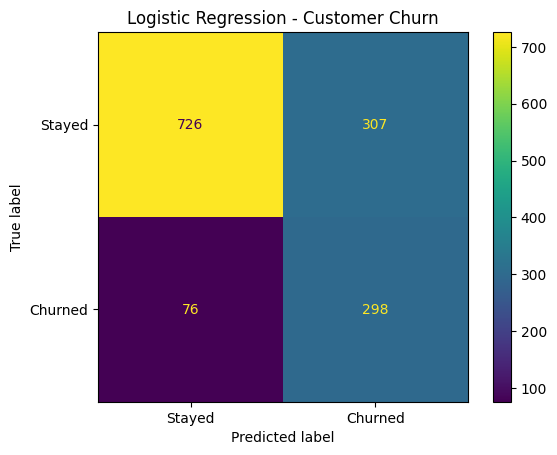

Accuracy: 0.7278


In [9]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict customer churn
y_pred_lr = model_lr.predict(X_test)

# Display evaluation results
print("Classification Report:")
print(classification_report(y_test, y_pred_lr))

# Plot confusion matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=["Stayed", "Churned"]
)

disp.plot()
plt.title("Logistic Regression - Customer Churn")
plt.show()

print("Accuracy:", round(accuracy_score(y_test, y_pred_lr), 4))


In [10]:

from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
model_rf = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train the model
model_rf.fit(X_train, y_train)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1033
           1       0.63      0.49      0.55       374

    accuracy                           0.79      1407
   macro avg       0.73      0.69      0.71      1407
weighted avg       0.78      0.79      0.78      1407



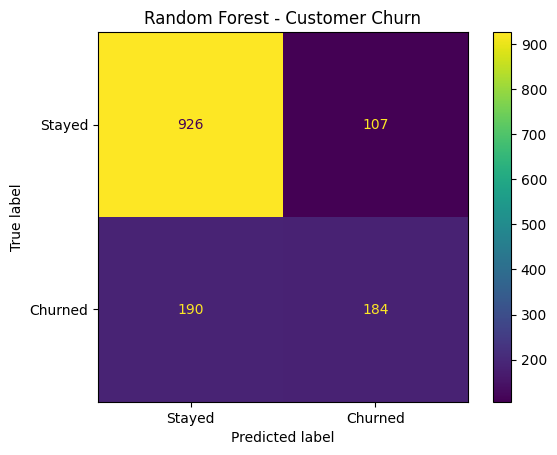

In [11]:

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predict customer churn
y_pred_rf = model_rf.predict(X_test)

print("Random Forest Classification Report:")
print(classification_report(y_test, y_pred_rf))

# Plot confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Stayed", "Churned"]
)

disp.plot()
plt.title("Random Forest - Customer Churn")
plt.show()


In [12]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Logistic Regression": [
        accuracy_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_lr, zero_division=0),
        recall_score(y_test, y_pred_lr, zero_division=0),
        f1_score(y_test, y_pred_lr, zero_division=0)
    ],
    "Random Forest": [
        accuracy_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_rf, zero_division=0),
        recall_score(y_test, y_pred_rf, zero_division=0),
        f1_score(y_test, y_pred_rf, zero_division=0)
    ]
})

print(comparison.round(4).to_string(index=False))


   Metric  Logistic Regression  Random Forest
 Accuracy               0.7278         0.7889
Precision               0.4926         0.6323
   Recall               0.7968         0.4920
 F1-Score               0.6088         0.5534


In [13]:

import joblib

# Save the final Logistic Regression model
joblib.dump(model_lr, "customer_churn_model.joblib")

# Save the feature column names
joblib.dump(list(X.columns), "customer_churn_features.joblib")

print("Customer Churn model saved successfully!")


Customer Churn model saved successfully!


In [14]:

from google.colab import files

files.download("customer_churn_model.joblib")
files.download("customer_churn_features.joblib")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>